## PVSCM 2024 Q1 vs 2025 Q1: Excel CAPEX vs ENPAX CAPEX

This notebook compares the total CAPEX from the PVSCM Excel models with the CAPEX modeled by the ENPAX utility-scale solar + battery models.

| ENPAX model | Excel source | Dollar year |
|---|---|---|
| `solar_bess_2024Q1` | PVSCM 2024, `UPV 2024Q1` inputs | **2023 USD** (CPI-U = 304.7) |
| `solar_bess_2025Q1` | PVSCM 2025, `UPV 2025Q1` inputs ([data.nlr.gov/submissions/304](https://data.nlr.gov/submissions/304)) | **2024 USD** (CPI-U = 313.7) |

The comparison uses total installed cost at modeled market price (MMP), in $/kWdc. It covers the 100 MWdc benchmark system with storage (240 MWh) and without it.

Sections 1–3 report each model in its own dollar year (nominal). Section 4 restates the 2024 Q1 values in 2024 USD so the two vintages can be compared directly.

### Setup

This notebook needs ENPAX plus the optional example dependencies (JupyterLab, ipykernel, matplotlib, and jinja2). From the repository root, install ENPAX in editable mode with them:

```bash
pip install -e ".[examples]"
```

Then select the Python environment where you installed ENPAX as the notebook kernel. In VS Code, use **Select Kernel** in the notebook toolbar.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# Path setup
# ---------------------------------------------------------------------------
current_dir = os.getcwd()
project_root = current_dir
while project_root != os.path.dirname(project_root):
    if os.path.exists(os.path.join(project_root, "enpax")):
        break
    project_root = os.path.dirname(project_root)
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from enpax.models.solar_bess_2024Q1 import SolarBESS2024Q1CostModel
from enpax.models.solar_bess_2025Q1 import SolarBESS2025Q1CostModel

DOLLAR_YEAR = {"2024 Q1": "2023 USD", "2025 Q1": "2024 USD"}
CPI_U = {"2024 Q1": 304.7, "2025 Q1": 313.7}

### 1. Excel CAPEX

Each value is the System sheet MMP total (`SystemMMP`) of the PVSCM workbook at the default 100 MWdc system size, calculated with **Include ESS** on and off. Values are in each workbook's own dollar year: 2023 USD for PVSCM 2024 and 2024 USD for PVSCM 2025.

The 2024 workbook was saved at 200 MWdc, so it was recalculated at 100 MWdc. The recalculation reproduces each workbook's saved totals exactly before the size change.

In [2]:
EXCEL_CAPEX = {
    # (model year, case): total CAPEX at MMP, $/kWdc, in that model's dollar year
    ("2024 Q1", "PV + ESS"): 1994.9913685796273,   # 2023 USD
    ("2024 Q1", "PV only"):  1118.4967180796275,   # 2023 USD
    ("2025 Q1", "PV + ESS"): 1806.126591386973,    # 2024 USD
    ("2025 Q1", "PV only"):  1115.2902750724597,   # 2024 USD
}

### 2. ENPAX CAPEX

Both models run with their default inputs, which are the 100 MWdc benchmark system. Only `IncludeESS` changes between cases.

The ENPAX CAPEX is grouped into the eight PVSCM System categories. The ENPAX battery cost is split into `li_ion` and `bi_directional_inverter`, and the two are summed into ESS.

In [3]:
MODELS = {"2024 Q1": SolarBESS2024Q1CostModel, "2025 Q1": SolarBESS2025Q1CostModel}

# PVSCM System-sheet category -> ENPAX subsystem keys
CATEGORIES = {
    "Module":     ["pv_module"],
    "Inverter":   ["three_phase_inverter"],
    "ESS":        ["li_ion", "bi_directional_inverter"],
    "SBOS":       ["sbos"],
    "EBOS":       ["ebos"],
    "Fieldwork":  ["fieldwork"],
    "Officework": ["officework"],
    "Other":      ["other"],
}

totals, breakdown = [], {}
for (year, case), excel in EXCEL_CAPEX.items():
    model = MODELS[year](params={"IncludeESS": case == "PV + ESS"})
    sub = model.get_cost_breakdown()
    breakdown[(year, case)] = {cat: sum(sub[k] for k in keys) for cat, keys in CATEGORIES.items()}
    totals.append({
        "Model year": year,
        "Case": case,
        "Dollar year": DOLLAR_YEAR[year],
        "Excel CAPEX ($/kWdc)": excel,
        "ENPAX CAPEX ($/kWdc)": sub["total_project_cost_per_kwdc"],
    })

comparison = pd.DataFrame(totals)
diff = comparison["ENPAX CAPEX ($/kWdc)"] - comparison["Excel CAPEX ($/kWdc)"]
# Treat floating-point noise (< $0.001/kWdc) as an exact match
comparison["Difference ($/kWdc)"] = diff.mask(diff.abs() < 1e-3, 0.0)
comparison["Difference (%)"] = 100 * comparison["Difference ($/kWdc)"] / comparison["Excel CAPEX ($/kWdc)"]

comparison.style.format({
    "Excel CAPEX ($/kWdc)": "{:,.2f}",
    "ENPAX CAPEX ($/kWdc)": "{:,.2f}",
    "Difference ($/kWdc)": "{:+,.2f}",
    "Difference (%)": "{:+.2f}%",
}).hide(axis="index")

Model year,Case,Dollar year,Excel CAPEX ($/kWdc),ENPAX CAPEX ($/kWdc),Difference ($/kWdc),Difference (%)
2024 Q1,PV + ESS,2023 USD,"1,994.99","1,994.99",+0.00,+0.00%
2024 Q1,PV only,2023 USD,"1,118.50","1,118.50",+0.00,+0.00%
2025 Q1,PV + ESS,2024 USD,"1,806.13","1,806.13",+0.00,+0.00%
2025 Q1,PV only,2024 USD,"1,115.29","1,115.29",+0.00,+0.00%


In [4]:
# ENPAX CAPEX by PVSCM System category ($/kWdc, nominal)
categories = pd.DataFrame(breakdown).T
categories.index = [f"{year} {case} ({DOLLAR_YEAR[year]})" for year, case in categories.index]
categories["Total"] = categories.sum(axis=1)
categories.style.format("{:,.2f}")

,Module,Inverter,ESS,SBOS,EBOS,Fieldwork,Officework,Other,Total
2024 Q1 PV + ESS (2023 USD),336.00,33.33,547.20,149.32,185.60,447.11,62.20,234.21,"1,994.99"
2024 Q1 PV only (2023 USD),336.00,33.33,0.00,139.72,185.60,228.59,62.20,133.04,"1,118.50"
2025 Q1 PV + ESS (2024 USD),291.21,32.31,436.87,154.75,230.60,384.81,70.28,205.30,"1,806.13"
2025 Q1 PV only (2024 USD),291.21,32.31,0.00,141.11,230.60,220.81,70.28,128.96,"1,115.29"


### 3. Excel total vs ENPAX by category

For each model vintage and case, the left bar is the Excel total and the right bar is ENPAX, stacked by PVSCM System category. The label above each pair is the ENPAX difference from Excel ("match" when they agree to within $0.001/kWdc). Values are nominal, in each model's own dollar year.

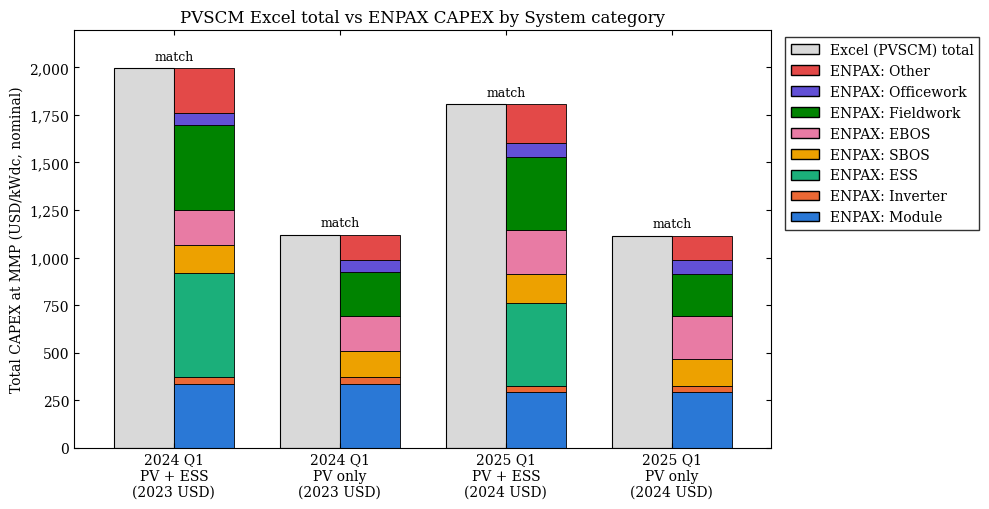

In [5]:
# Categorical slots in fixed order; the Excel total uses a neutral gray
CATEGORY_COLORS = {
    "Module":     "#2a78d6",
    "Inverter":   "#eb6834",
    "ESS":        "#1baf7a",
    "SBOS":       "#eda100",
    "EBOS":       "#e87ba4",
    "Fieldwork":  "#008300",
    "Officework": "#6250d6",
    "Other":      "#e34948",
}
EXCEL_COLOR = "#d9d9d9"
EDGE = "black"

groups = list(EXCEL_CAPEX)
x = np.arange(len(groups))
width = 0.36

with plt.rc_context({
    "font.family": "serif",
    "font.size": 10,
    "axes.edgecolor": EDGE,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
}):
    fig, ax = plt.subplots(figsize=(10, 5.2))

    excel_vals = [EXCEL_CAPEX[g] for g in groups]
    ax.bar(x - width / 2, excel_vals, width, color=EXCEL_COLOR, edgecolor=EDGE,
           linewidth=0.8, label="Excel (PVSCM) total")

    bottom = np.zeros(len(groups))
    for cat, color in CATEGORY_COLORS.items():
        vals = np.array([breakdown[g][cat] for g in groups])
        ax.bar(x + width / 2, vals, width, bottom=bottom, color=color,
               edgecolor=EDGE, linewidth=0.6)
        bottom += vals

    top = max(max(excel_vals), bottom.max())
    for xi, (_, row) in zip(x, comparison.iterrows()):
        pair_top = max(row["Excel CAPEX ($/kWdc)"], row["ENPAX CAPEX ($/kWdc)"])
        pct = row["Difference (%)"]
        label = "match" if pct == 0 else f"{pct:+.1f}%"
        ax.text(xi, pair_top + 0.015 * top, label, ha="center", va="bottom", fontsize=9)

    for spine in ax.spines.values():
        spine.set_visible(True)
    ax.set_xticks(x, [f"{year}\n{case}\n({DOLLAR_YEAR[year]})" for year, case in groups])
    ax.set_xlim(-0.6, len(groups) - 0.4)
    ax.set_ylim(0, top * 1.10)
    ax.set_ylabel("Total CAPEX at MMP (USD/kWdc, nominal)")
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
    ax.set_title("PVSCM Excel total vs ENPAX CAPEX by System category")

    handles = [Patch(facecolor=EXCEL_COLOR, edgecolor=EDGE, label="Excel (PVSCM) total")]
    handles += [Patch(facecolor=c, edgecolor=EDGE, label=f"ENPAX: {cat}")
                for cat, c in reversed(CATEGORY_COLORS.items())]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=True, edgecolor=EDGE, fancybox=False)
    fig.tight_layout()
    plt.show()

### 4. Observations

**Dollar years.** `solar_bess_2024Q1` (PVSCM 2024 Q1) is in **2023 USD** (CPI-U = 304.7). `solar_bess_2025Q1` (PVSCM 2025 Q1) is in **2024 USD** (CPI-U = 313.7). The plot and tables above are nominal. To compare the two vintages directly, the table below restates 2024 Q1 in 2024 USD by multiplying by 313.7 / 304.7 ≈ 1.030.

- **ENPAX vs Excel:** ENPAX reproduces the Excel total CAPEX for both vintages, with and without storage.
- **PV + ESS:** in 2024 USD, CAPEX falls from about $2,054/kWdc (2024 Q1) to $1,806/kWdc (2025 Q1), about −12%. The largest reductions are ESS hardware (about −$126/kWdc) and fieldwork (about −$76/kWdc, mostly ESS installation labor), followed by modules (about −$55/kWdc) and Other (about −$36/kWdc). EBOS rises by about $40/kWdc.
- **PV only:** in 2024 USD, CAPEX falls from about $1,152/kWdc to $1,115/kWdc, about −3%. Lower module and fieldwork costs are partly offset by higher EBOS.
- In nominal terms the PV-only totals look nearly flat ($1,118 vs $1,115/kWdc). That hides the real decline, because the two vintages are in different dollar years.

In [6]:
# 2024 Q1 restated in 2024 USD for a constant-dollar comparison
to_2024_usd = CPI_U["2025 Q1"] / CPI_U["2024 Q1"]

real = []
for case in ("PV + ESS", "PV only"):
    old = pd.Series(breakdown[("2024 Q1", case)]) * to_2024_usd
    new = pd.Series(breakdown[("2025 Q1", case)])
    for cat in list(CATEGORIES) + ["Total"]:
        o = old.sum() if cat == "Total" else old[cat]
        n = new.sum() if cat == "Total" else new[cat]
        real.append({"Case": case, "Category": cat,
                     "2024 Q1 (2024 USD)": o, "2025 Q1 (2024 USD)": n,
                     "Change ($/kWdc)": n - o, "Change (%)": 100 * (n - o) / o if o else np.nan})

pd.DataFrame(real).style.format({
    "2024 Q1 (2024 USD)": "{:,.2f}",
    "2025 Q1 (2024 USD)": "{:,.2f}",
    "Change ($/kWdc)": "{:+,.2f}",
    "Change (%)": "{:+.1f}%",
}, na_rep="—").hide(axis="index")

Case,Category,2024 Q1 (2024 USD),2025 Q1 (2024 USD),Change ($/kWdc),Change (%)
PV + ESS,Module,345.92,291.21,-54.71,-15.8%
PV + ESS,Inverter,34.32,32.31,-2.01,-5.9%
PV + ESS,ESS,563.36,436.87,-126.49,-22.5%
PV + ESS,SBOS,153.73,154.75,+1.02,+0.7%
PV + ESS,EBOS,191.09,230.60,+39.51,+20.7%
PV + ESS,Fieldwork,460.32,384.81,-75.51,-16.4%
PV + ESS,Officework,64.04,70.28,+6.24,+9.7%
PV + ESS,Other,241.13,205.30,-35.83,-14.9%
PV + ESS,Total,"2,053.92","1,806.13",-247.79,-12.1%
PV only,Module,345.92,291.21,-54.71,-15.8%
